# Notebook 04 — Model Evaluation & Demo

Side-by-side comparison of Classical ML vs MobileNetV2 and live demo inference.

In [1]:
import os, sys
sys.path.insert(0, '..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import joblib
from PIL import Image
from torchvision import transforms
import seaborn as sns

from src.dataset import CLASS_NAMES, load_images_from_folder, OrangeDataset
from src.classical_model import extract_features_batch
from src.dl_model import build_mobilenet, evaluate, predict_single
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

DATA_DIR = '../data/raw'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


## 1. Load Models & Test Data

In [2]:
svm = joblib.load('../models/svm_model.joblib')
rf  = joblib.load('../models/rf_model.joblib')

model = build_mobilenet(num_classes=4).to(DEVICE)
model.load_state_dict(torch.load('../models/mobilenet_best.pth', map_location=DEVICE))
model.eval()

X_test, y_test = load_images_from_folder(os.path.join(DATA_DIR, 'test'))
F_test = extract_features_batch(X_test)

criterion = torch.nn.CrossEntropyLoss()
test_ds = OrangeDataset(X_test, y_test, augment=False)
from torch.utils.data import DataLoader
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)
_, _, dl_preds, dl_labels = evaluate(model, test_loader, criterion, DEVICE)

svm_preds = svm.predict(F_test)
rf_preds  = rf.predict(F_test)
print("Predictions collected.")


Predictions collected.


## 2. Metrics Comparison Table

In [3]:
def metrics(y_true, y_pred, name):
    return {
        'Model': name,
        'Accuracy':  round(accuracy_score(y_true, y_pred), 4),
        'Precision': round(precision_score(y_true, y_pred, average='macro', zero_division=0), 4),
        'Recall':    round(recall_score(y_true, y_pred, average='macro', zero_division=0), 4),
        'F1-Score':  round(f1_score(y_true, y_pred, average='macro', zero_division=0), 4),
    }

rows = [
    metrics(y_test,   svm_preds,  'SVM (Classical)'),
    metrics(y_test,   rf_preds,   'Random Forest (Classical)'),
    metrics(dl_labels, dl_preds,  'MobileNetV2 (Deep Learning)'),
]
df = pd.DataFrame(rows).set_index('Model')
print(df.to_string())
df.to_csv('../report/metrics_comparison.csv')


                             Accuracy  Precision  Recall  F1-Score
Model                                                             
SVM (Classical)                0.9798     0.9773  0.9773    0.9773
Random Forest (Classical)      0.9697     0.9664  0.9659    0.9659
MobileNetV2 (Deep Learning)    0.9798     0.9773  0.9773    0.9773


## 3. Visual Comparison Bar Chart

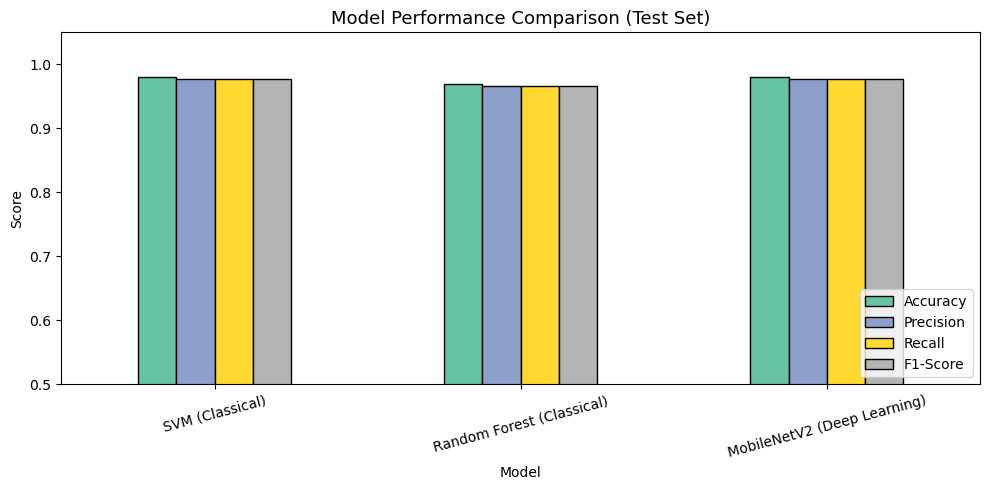

In [4]:
ax = df.plot(kind='bar', figsize=(10, 5), rot=15, colormap='Set2', edgecolor='black')
ax.set_title('Model Performance Comparison (Test Set)', fontsize=13)
ax.set_ylabel('Score')
ax.set_ylim(0.5, 1.05)
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('../report/model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


## 4. Live Demo Inference

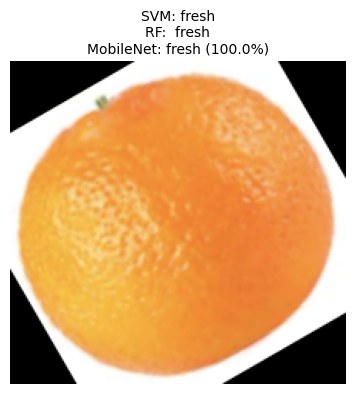

('fresh', 'fresh', 'fresh')

In [5]:
transform_val = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

def demo_image(image_path):
    img = Image.open(image_path).convert('RGB')
    img_np = np.array(img.resize((224, 224)))

    feat = extract_features_batch(np.expand_dims(img_np, 0))
    svm_pred  = CLASS_NAMES[svm.predict(feat)[0]]
    rf_pred   = CLASS_NAMES[rf.predict(feat)[0]]

    tensor = transform_val(img)
    dl_pred, dl_conf = predict_single(model, tensor, DEVICE, CLASS_NAMES)

    fig, ax = plt.subplots(1, 1, figsize=(4, 4))
    ax.imshow(img)
    ax.axis('off')
    ax.set_title(f"SVM: {svm_pred}\nRF:  {rf_pred}\nMobileNet: {dl_pred} ({dl_conf:.1%})", fontsize=10)
    plt.tight_layout()
    plt.show()
    return svm_pred, rf_pred, dl_pred

# Run on a sample test image
sample_path = os.path.join(DATA_DIR, 'test', 'fresh', [f for f in os.listdir(os.path.join(DATA_DIR, 'test', 'fresh'))][0])
demo_image(sample_path)
